# Création des visualisations : Consommation électrique française (2019–2024)

Ce notebook présente la création des graphiques destinées à une infographie de vulgarisation scientifique sur la consommation électrique française entre 2019 et 2024.

Les visualisations sont réalisées avec Pandas et Matplotlib, à partir des données RTE éCO2mix préalablement nettoyées et analysées.

Les graphiques sont exportés au format SVG afin d'être intégrés et mis en forme des Inkscape, tout en préservant leur fidélité aux données.

In [1]:
# Bibliothèques
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# Configuration des exports SVG
dossier_exports = Path("../exports")
dossier_exports.mkdir(parents=True, exist_ok=True)
plt.rcParams["svg.fonttype"] = "none"

# Chargement des données préparées
df = pd.read_csv("../processed/eco2mix_analyse.csv", sep=",", keep_default_na=False)

df_wip = df.copy()
df_wip.head()

,date,heure,horodatage_source,conso_mw,saison,annee,mois,jour_semaine_numero,jour_du_mois,semaine_weekend,nom_mois,heure_numero
0,2024-12-31,23:30:00,2024-12-31 23:30:00.000 +0100,65159,Hiver,2024,12,2,31,Semaine,Décembre,23
1,2024-12-31,23:00:00,2024-12-31 23:00:00.000 +0100,65437,Hiver,2024,12,2,31,Semaine,Décembre,23
2,2024-12-31,22:30:00,2024-12-31 22:30:00.000 +0100,63816,Hiver,2024,12,2,31,Semaine,Décembre,22
3,2024-12-31,22:00:00,2024-12-31 22:00:00.000 +0100,63063,Hiver,2024,12,2,31,Semaine,Décembre,22
4,2024-12-31,21:30:00,2024-12-31 21:30:00.000 +0100,63946,Hiver,2024,12,2,31,Semaine,Décembre,21


### 1. Variations mensuelles et saisonnière de la consommation électrique

Objectif : Identifier les mois et les saisons présentant les niveaux moyens de consommation électrique les plus élevés et les plus faibles sur la période 2019-2024.

Méthode : Calculer la puissance moyenne appelée pour chaque couple année-mois, puis établir un profil mensuel moyen en accordant le même poids aux six années. Calculer également la puissance moyenne appelée pour chaque saison et son écart relatif à la moyenne globale de la période.

Visualisation :  courbe représentant la puissance moyenne appelée (MW) de janvier à décembre. Les écarts saisonniers en pourcentage par rapport à la moyenne globale seront calculés dans python, puis présentées sous forme de KPI dans l'infographie réalisée avec Inkscape.

In [2]:
# Calcul du profil mensuel moyen (même poids pour chaque année)
moyennes_mensuelles_par_annee = df_wip.groupby(["annee", "mois"])["conso_mw"].mean()
profil_mensuel = moyennes_mensuelles_par_annee.groupby(level="mois").mean()

# Libellés des mois pour le graphique
noms_mois_abreges = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Aoû", "Sep", "Oct", "Nov", "Déc"]

# Contrôle des valeurs extrêmes
print(f"Minimum : {profil_mensuel.min():.2f} MW (mois {profil_mensuel.idxmin()})")
print(f"Maximum : {profil_mensuel.max():.2f} MW (mois {profil_mensuel.idxmax()})")

Minimum : 41785.29 MW (mois 8)
Maximum : 67925.83 MW (mois 1)


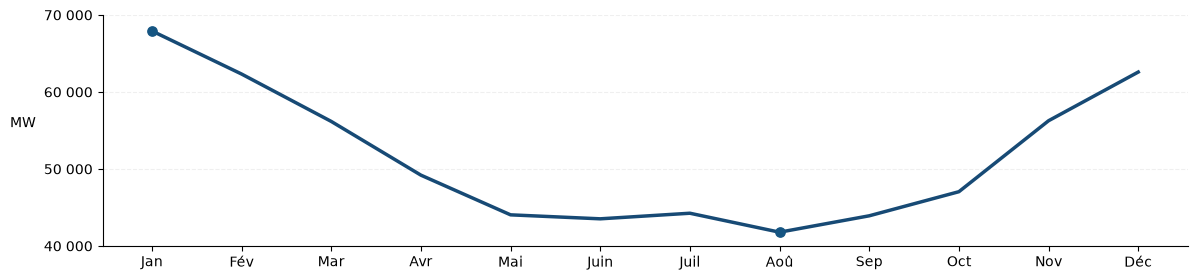

In [3]:
# Création de la figure et personnalisation des axes
fig = plt.figure(figsize=(14, 3))
ax = fig.add_subplot(111)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.scatter([1, 8], [profil_mensuel.loc[1], profil_mensuel.loc[8]], color="#155582", s=45, zorder=5)


# Tracé du profil mensuel
ax.plot(profil_mensuel.index, profil_mensuel.values, color="#174A75", linewidth=2.5)

# Graduations et unités
ax.set_xticks(profil_mensuel.index, noms_mois_abreges)
ax.set_yticks(range(40000, 70001, 10000))
ax.set_ylim(40000, 70000)
ax.set_ylabel("MW", rotation=0, labelpad=15)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", " ")))

# Export SVG
#fig.savefig(dossier_exports / "profil_mensuel.svg", format="svg", transparent=True, bbox_inches="tight")
plt.show()

In [14]:
# Calcul de la puissance moyenne appelée par saison et sur l'ensemble de la période
moyennes_saisonnieres_par_annee = df_wip.groupby(["annee", "saison"])["conso_mw"].mean()
moyennes_saisonnieres = moyennes_saisonnieres_par_annee.groupby(level="saison").mean()

# Moyenne globale de la période
moyenne_globale = df_wip["conso_mw"].mean()

# Calcul des écarts relatifs à la moyenne globale (%)
ecarts_saisonniers_pct = ((moyennes_saisonnieres - moyenne_globale) / moyenne_globale) * 100

# Création du tableau récapitulatif
df_saisons = pd.DataFrame({"Moyenne (MW)": moyennes_saisonnieres, "Moyenne globale (MW)": moyenne_globale, "Écart à la moyenne (pct)": ecarts_saisonniers_pct})

# Affichage avec deux décimales
df_saisons.round(2)

,Moyenne (MW),Moyenne globale (MW),Écart à la moyenne (pct)
saison,,,
Automne,49050.69,51540.91,-4.83
Hiver,64331.88,51540.91,24.82
Printemps,49809.52,51540.91,-3.36
Été,43181.59,51540.91,-16.22


### 2. Variations horaires de la consommation électrique : semaine et week-end

Objectif : Identifier les heures de forte et de faible consommation électrique et comparer les profils horaires des jours de semaine et des week-ends sur la période 2019-2024.

Méthode : Calculer la puissance moyenne appelée pour chaque heure de la journée, en distinguant les jours de semaine des jours de week-end.

Visualisation : Deux courbes représentant les profils horaires moyens (MW) de 0 h à 23 h, l'une pour les jours de semaine et l'autre pour les week-ends.

In [13]:
# Calcul du profil horaire moyen sur la période 2019-2024
profil_horaire = df_wip.groupby("heure_numero")["conso_mw"].mean()
profil_semaine_week_end = df_wip.groupby(["heure_numero", "semaine_weekend"])["conso_mw"].mean()
profil_semaine = profil_semaine_week_end.xs("Semaine", level="semaine_weekend")
profil_weekend = profil_semaine_week_end.xs("Week end", level="semaine_weekend")

# Contrôle des valeurs extrêmes
print(f"Minimum : {profil_horaire.min():.2f} MW (heure {profil_horaire.idxmin()})")
print(f"Maximum : {profil_horaire.max():.2f} MW (heure {profil_horaire.idxmax()})")

Minimum : 43312.53 MW (heure 4)
Maximum : 56917.99 MW (heure 12)


In [6]:
# Vérification du nombre de moyennes horaires
print(f"Nombre de moyennes : {len(profil_semaine_week_end)}")

# Contrôle des valeurs extrêmes par type de jour
for categories, valeurs in profil_semaine_week_end.groupby(level="semaine_weekend"):
    print(f"\n{categories}")
    print(f"Minimum : {valeurs.min():.2f} MW")
    print(f"Maximum : {valeurs.max():.2f} MW")

Nombre de moyennes : 48

Semaine
Minimum : 43893.31 MW
Maximum : 58861.72 MW

Week end
Minimum : 41532.98 MW
Maximum : 52055.57 MW


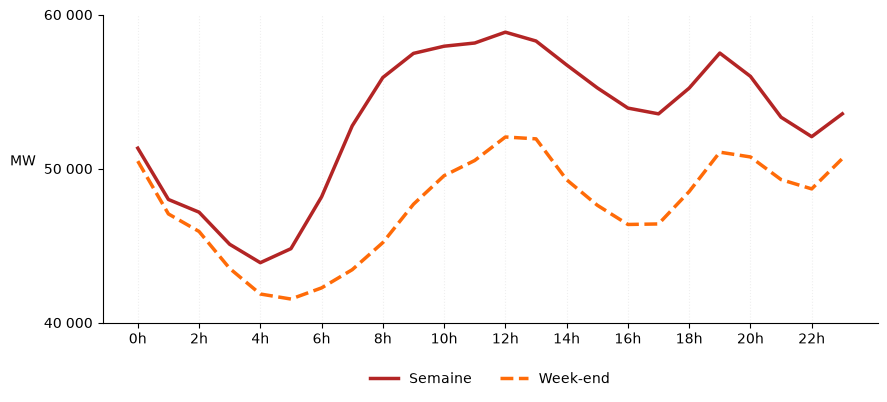

In [7]:
# Création de la figure et personnalisation des axes
fig = plt.figure(figsize=(10, 4))
ax = fig.add_subplot(111)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle=":", alpha=0.2)

# Tracé des profils horaires : semaine et week-end
ax.plot(profil_semaine.index, profil_semaine.values, color="#B32525", linewidth=2.5, label="Semaine")
ax.plot(profil_weekend.index, profil_weekend.values, color="#FF6B08", linewidth=2.5, linestyle="--", label="Week-end")

# Graduations et unités
ax.set_ylim(40000, 60000)
#ax.set_xlim(0,23)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h}h" for h in range(0, 24, 2)])
ax.set_yticks(range(40000, 60001, 10000))
ax.set_ylabel("MW", rotation=0, labelpad=15)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", " ")))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)

# Export SVG
#fig.savefig(dossier_exports / "profil_horaire_semaine_weekend.svg", format="svg", transparent=True, bbox_inches="tight")
plt.show()

In [8]:
# Calcul de la puissance moyenne appelée en semaine et le week-end
moyennes_semaine_weekend = df_wip.groupby("semaine_weekend")["conso_mw"].mean()

# Calcul de la diminution relative le week-end par rapport à la semaine
ecart_relatif_weekend = ((moyennes_semaine_weekend["Semaine"] - moyennes_semaine_weekend["Week end"]) / moyennes_semaine_weekend["Semaine"])*100

ecart_relatif_weekend

np.float64(10.460614444933778)

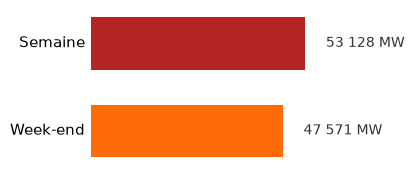

In [9]:
# Création de la figure et personnalisation des axes
fig = plt.figure(figsize=(4, 2))
ax = fig.add_subplot(111)
ax.axis("off")

# Tracé des profils horaires : semaine et week-end
barres = ax.barh(moyennes_semaine_weekend.index, moyennes_semaine_weekend.values, height=0.6, color=[ "#B32525", "#FF6B08"])

# Affichage des valeurs en MW à droite des barres
ax.bar_label(barres, fmt=lambda x: f"{x:,.0f} MW".replace(",", " "), label_type="edge", color="#333333", padding=15)

# Positionnement des barres et des libellés
ax.invert_yaxis()
ax.set_xlim(-12000, 65000)
for barre, libelle in zip(barres, ["Semaine", "Week-end"]):
    ax.text(-1500, barre.get_y() + barre.get_height() / 2, libelle, ha="right", va="center", fontsize=11)

# Export SVG
#fig.savefig(dossier_exports / "comparaison_semaine_weekend.svg", format="svg", transparent=True, bbox_inches="tight")
plt.show()

### Évolution annuelle de la consommation électrique (2019-2024)

Objectif : Observer l'évolution de la consommation électrique française entre 2019-2024 et identifier les variations d'une année à l'autre.

Méthode : Calculer la puissance moyenne appelée (MW) pour chaque année de la période 2019-2024.

Visualisation :  Un diagramme en barres verticuales représentant la puissance moyenne annuelle (MW) pour chacun des six années, afin de visualiser les fluctuations.

In [10]:
# Calcul de la puissance moyenne appelée pour chaque année (2019–2024)
moyennes_annuelles = df_wip.groupby("annee")["conso_mw"].mean()
moyennes_annuelles

annee
2019    53707.436301
2020    50840.467953
2021    53492.347831
2022    51387.245320
2023    49722.932877
2024    50100.899932
Name: conso_mw, dtype: float64

In [11]:
# Calcul de la variation relative de la puissance moyenne appelée entre 2019 et 2024
variation_pct = ((moyennes_annuelles[2024] - moyennes_annuelles[2019]) / moyennes_annuelles[2019])*100
variation_pct

np.float64(-6.715152720078511)

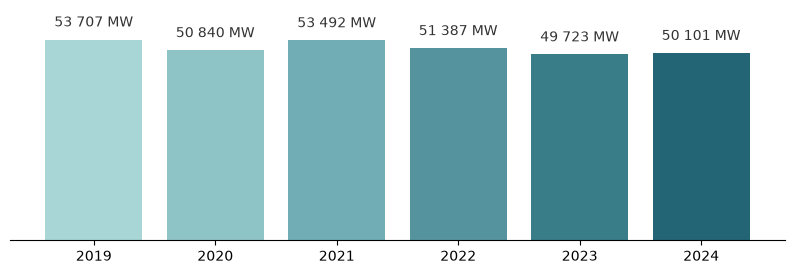

In [12]:

# Création de la figure et personnalisation des axes
fig = plt.figure(figsize=(10, 3))
ax = fig.add_subplot(111)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.set_ylim(bottom=0)
ax.set_yticks([])

# Palette de couleurs : progression du turquoise au bleu pétrole
couleurs = ["#A8D5D5", "#8FC4C7", "#70ADB4", "#55949F", "#397D89", "#236575"]

# Tracé des puissances moyennes annuelles (2019–2024)
barres_annuelles = ax.bar(moyennes_annuelles.index, moyennes_annuelles.values, color=couleurs )

# Affichage des valeurs en MW au-dessus des barres
ax.bar_label(barres_annuelles, fmt=lambda x: f"{x:,.0f} MW".replace(",", " "), label_type="edge", color="#333333", padding=7)
ax.set_ylim(0, moyennes_annuelles.max() * 1.15)

# Export SVG
#fig.savefig(dossier_exports / "evolution_annuelle.svg", format="svg", transparent=True, bbox_inches="tight")
plt.show()